# 4. Implementación de los modelos base

En esta sección del trabajo se describe cómo fue el proceso de entrenamiento de las redes Mask R-CNN, YOLOv8-seg y SOLOv2: el protocolo común, la selección de hiperparámetros, las 15 corridas, su costo computacional, las curvas de entrenamiento y el estudio piloto.

En la celda siguiente se cargan las rutas y funciones del proyecto. No se entrena nada: las tablas y figuras se obtienen de los resultados guardados de las 15 corridas.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Image, Markdown
from itertools import combinations
import estadistica_instancias as EI

LIT = ROOT / 'literatura' / 'instancias'
CORR = ROOT / 'results' / 'instancias' / 'corridas'
MODELOS = {'maskrcnn': 'Mask R-CNN', 'yolov8seg': 'YOLOv8-seg', 'solov2': 'SOLOv2'}
orden = ['maskrcnn', 'yolov8seg', 'solov2']
pd.set_option('display.max_colwidth', 90)
print('Corridas encontradas:', sorted(p.name for p in CORR.glob('*_s*') if (p / 'metricas.json').exists()))

Corridas encontradas: ['maskrcnn_s42', 'maskrcnn_s43', 'maskrcnn_s44', 'maskrcnn_s45', 'maskrcnn_s46', 'solov2_s42', 'solov2_s43', 'solov2_s44', 'solov2_s45', 'solov2_s46', 'yolov8seg_s42', 'yolov8seg_s43', 'yolov8seg_s44', 'yolov8seg_s45', 'yolov8seg_s46']


## 4.1 Protocolo experimental

Se entrenaron los tres modelos base (Mask R-CNN, YOLOv8-seg y SOLOv2) con cinco semillas cada uno (42 a 46): 15 corridas en total. Todas las corridas comparten el mismo protocolo:

- **Partición.** La partición agrupada congelada del EDA (`results/eda/particion.csv`): 744 imágenes de entrenamiento, 93 de validación y 108 de prueba. En prueba hay 14 grupos (sesiones o escenas de captura). Ninguna sesión aparece en más de un conjunto.
- **Entrada.** Imagen completa de 1280×720, sin reescalar ni recortar, porque el diámetro mediano de un tornillo es de 10.6 px (sección 2.5). Mask R-CNN y SOLOv2 usan solo volteo horizontal. YOLOv8-seg usa los aumentos por defecto de ultralytics: mosaico (apagado en las últimas 10 épocas), variación de color HSV, traslación de ±10 %, escala de ±50 % y volteo horizontal.
- **Inicialización.** Pesos preentrenados en COCO para los tres modelos.
- **Selección del modelo.** Se guarda la mejor época según el conjunto de validación: AP de máscara en Mask R-CNN y SOLOv2, y el *fitness* de ultralytics en YOLOv8-seg. El conjunto de prueba se evalúa una sola vez por corrida.
- **Confianza mínima para aceptar una detección.** Para calcular F1 y PQ, se descartan las predicciones cuyo puntaje de confianza queda por debajo de este corte. El corte se elige en validación para maximizar el F1 medio por imagen y se mantiene fijo en prueba. AP se calcula con todos los puntajes, sin fijar un corte.

Tabla 4.1. Configuración por modelo.

| Modelo | Tipo | Parámetros | Épocas | Lote | Optimizador | Marco |
|---|---|---|---|---|---|---|
| Mask R-CNN (ResNet-50-FPN) | Dos etapas, con cajas | 43 922 395 | 12 | 2 | SGD, momento 0.9, calentamiento + coseno, lr 0.0025 × lote | torchvision 0.26 |
| YOLOv8n-seg | Una etapa, con cajas | 3 263 811 | 40 | 4 | Valores por defecto de ultralytics | ultralytics 8.4.207 |
| SOLOv2 (ResNet-50-FPN) | Una etapa, sin cajas | 46 228 801 | 12 | 2 | SGD, lr 0.01 × lote/16 (receta oficial `solov2_r50_fpn_1x_coco`) | MMDetection 3.3 |

Mask R-CNN usa anclas de 8 a 128 px en lugar de las de 32 a 512 px que trae torchvision por defecto, porque el 98,8 % de los tornillos son *small* según COCO (menos de 32×32 px) (sección 2.5).

**Hardware y reparto.** Las corridas se repartieron entre dos máquinas por semilla, no por modelo:
- semillas 42, 43 y 44 en una RTX 3060 Laptop de 6 GB;
- semillas 45 y 46 en una RTX 3050 Laptop de 6 GB.

Las dos usaron la misma configuración y las mismas versiones de los paquetes (`requirements_wdsd_dl_congelado.txt`). Así, cualquier efecto de la máquina cae por igual sobre los tres modelos.

### Selección de hiperparámetros

Los hiperparámetros se fijaron con tres criterios: partir de la receta oficial de cada implementación, que ya está validada en COCO; adaptarla a lo que mostró el EDA sobre el tamaño de los tornillos; y ajustarla a la memoria de una GPU de 6 GB. Las elecciones que dependen de los datos de WDSD, es decir, la época que se conserva y la confianza mínima de las detecciones, se toman con el conjunto de validación. El conjunto de prueba no interviene en ninguna elección.

**Tabla 4.1b.** Hiperparámetros y su justificación.

| Hiperparámetro | Valor | Justificación |
|---|---|---|
| Resolución de entrada | 1280×720, sin reescalar ni recortar, en los tres modelos (`imgsz` = 1280 en YOLOv8-seg; `min_size` = 720 y `max_size` = 1280 en Mask R-CNN) | El diámetro mediano de un tornillo es de 10,6 px. Reducir la imagen a la mitad lo dejaría en unos 6 px, demasiado poco para delimitar su máscara (sección 2.9 del EDA). |
| Anclas de Mask R-CNN | 8, 16, 32, 64 y 128 px, con proporciones 0,5, 1 y 2 | Las anclas por defecto de torchvision van de 32 a 512 px y están pensadas para objetos medianos y grandes. El 98,8 % de los tornillos es *small* según COCO (menos de 32×32 px). |
| Pesos iniciales | Preentrenados en COCO | Con 744 imágenes de entrenamiento, partir de características ya aprendidas acelera la convergencia y reduce el sobreajuste. |
| Tamaño de lote | 2 en Mask R-CNN y SOLOv2; 4 en YOLOv8n-seg | Cabe a resolución completa en las dos GPU de 6 GB, con un pico medido de unos 2,7 GB (tabla 4.3). YOLOv8n-seg es mucho más liviano y admite un lote mayor. |
| Tasa de aprendizaje | Mask R-CNN: 0,0025 × lote = 0,005. SOLOv2: 0,01 × lote / 16 = 0,00125. YOLOv8-seg: la de ultralytics | Se parte de la tasa de la receta oficial y se escala en proporción al tamaño del lote (regla de escalado lineal), para que cada paso tenga un tamaño comparable al de la receta original. |
| Optimizador y calendario | SGD con momento 0,9, decaimiento de pesos 10⁻⁴, calentamiento lineal y decaimiento coseno en Mask R-CNN y SOLOv2; optimizador automático de ultralytics en YOLOv8-seg | Es la configuración con la que se publicaron estos modelos. El calentamiento evita pasos grandes al inicio, cuando la cabeza nueva de una sola clase todavía es aleatoria, y el coseno reduce la tasa de forma suave hasta el final. |
| Número de épocas | 12 en Mask R-CNN y SOLOv2; 40 en YOLOv8-seg | 12 épocas es el calendario estándar «1x» de estos detectores. Un piloto de tiempos, con una época de cada modelo, midió cuántas épocas cabían en el tiempo de cómputo disponible; YOLOv8n-seg es más rápido por época y admite más. |
| Época que se conserva | La de mejor AP de máscara en validación (*fitness* de ultralytics en YOLOv8-seg) | Evita quedarse con una época sobreajustada. La figura 4.1 muestra que Mask R-CNN alcanza su máximo en las épocas 8 y 9. |
| Confianza mínima de una detección | La que maximiza el F1 medio por imagen en validación (columna «umbral (val)» de la tabla 4.2) | F1 y PQ dependen de qué detecciones se aceptan. Elegir el corte en validación y fijarlo en prueba evita ajustarlo con los datos de evaluación. |
| Aumento de datos | Volteo horizontal en Mask R-CNN y SOLOv2; mosaico, HSV, traslación, escala y volteo en YOLOv8-seg | Los tornillos no tienen una orientación preferente, así que el volteo no altera su apariencia. En YOLOv8-seg se conservan los aumentos con los que ultralytics entrena sus modelos. |
| Semillas | 42, 43, 44, 45 y 46 | Cinco repeticiones de cada configuración miden cuánto cambia el resultado por la inicialización y el orden de los datos (sección 4.5). |

Con estas elecciones, cada modelo trabaja a la escala de objetos de unos 10 px y dentro de los recursos disponibles, y los tres se comparan bajo el mismo protocolo de partición, selección y evaluación.

## 4.2 Corridas

Cada corrida deja en `results/instancias/corridas/<modelo>_s<semilla>/`:
- `resumen.json`: entorno, tiempo, memoria y métricas;
- `metricas.json`: AP, F1 y PQ en validación y prueba, y el umbral elegido en validación;
- `test_por_imagen.csv`: una fila por imagen de prueba (TP, FP, FN, F1, PQ), entrada de la sección 5;
- `preds_val.json` y `preds_test.json`: predicciones en formato COCO, para recalcular cualquier métrica sin reentrenar.

**Tabla 4.2.** Las 15 corridas.

In [4]:
filas = []
for d in sorted(CORR.glob('*_s*')):
    if not (d / 'resumen.json').exists():
        continue
    r = json.loads((d / 'resumen.json').read_text(encoding='utf8'))
    m = r['metricas']
    filas.append({'modelo': MODELOS[r['modelo']], 'semilla': r['semilla'], 'GPU': r['entorno']['gpu'].replace('NVIDIA GeForce ', ''),
                  'épocas': r['epocas'], 'min': round(r['s_total'] / 60, 1), 'umbral (val)': m['umbral_score'],
                  'val AP': round(m['val']['AP'], 3), 'test F1 img': round(m['test']['F1_img'], 3),
                  'test AP': round(m['test']['AP'], 3)})
corridas = pd.DataFrame(filas)
display(corridas)

,modelo,semilla,GPU,épocas,min,umbral (val),val AP,test F1 img,test AP
0,Mask R-CNN,42,RTX 3060 Laptop GPU,12,33.7,0.70,0.294,0.458,0.214
1,Mask R-CNN,43,RTX 3060 Laptop GPU,12,33.0,0.50,0.284,0.447,0.217
2,Mask R-CNN,44,RTX 3060 Laptop GPU,12,33.7,0.60,0.289,0.418,0.217
3,Mask R-CNN,45,RTX 3050 6GB Laptop GPU,12,76.0,0.60,0.282,0.450,0.214
4,Mask R-CNN,46,RTX 3050 6GB Laptop GPU,12,70.9,0.60,0.288,0.461,0.223
5,SOLOv2,42,RTX 3060 Laptop GPU,12,32.6,0.25,0.124,0.326,0.104
6,SOLOv2,43,RTX 3060 Laptop GPU,12,31.3,0.20,0.133,0.310,0.117
7,SOLOv2,44,RTX 3060 Laptop GPU,12,31.3,0.15,0.132,0.256,0.116
8,SOLOv2,45,RTX 3050 6GB Laptop GPU,12,56.3,0.20,0.132,0.305,0.111
9,SOLOv2,46,RTX 3050 6GB Laptop GPU,12,55.5,0.20,0.131,0.287,0.116


## 4.3 Costo computacional

**Tabla 4.3.** Costo computacional por corrida (entrenamiento + evaluación).

| Modelo | Minutos, RTX 3060 (3 semillas) | Minutos, RTX 3050 (2 semillas) | Memoria GPU pico (GB) |
|---|---|---|---|
| Mask R-CNN | 33.5 | 73.5 | 2.7 |
| YOLOv8-seg | 21.0 | 62.4 | 2.6 |
| SOLOv2 | 31.7 | 55.9 | ~2.6* |

\* Para SOLOv2 se toma el pico del registro de MMDetection durante el entrenamiento; el contador de PyTorch del script se reinicia dentro de MMDetection y da un valor menor que no corresponde al entrenamiento.

In [5]:
corridas.groupby(['modelo', 'GPU'])['min'].agg(['mean', 'count']).round(1)

mean  count
modelo     GPU                                 
Mask R-CNN RTX 3050 6GB Laptop GPU  73.4      2
           RTX 3060 Laptop GPU      33.5      3
SOLOv2     RTX 3050 6GB Laptop GPU  55.9      2
           RTX 3060 Laptop GPU      31.7      3
YOLOv8-seg RTX 3050 6GB Laptop GPU  62.4      2
           RTX 3060 Laptop GPU      21.0      3

## 4.4 Curvas de entrenamiento y validación

**Figura 4.1.** Pérdida de entrenamiento (arriba) y AP de máscara en validación (abajo) por época, una línea por semilla. Cada marco reporta su propia pérdida total, así que las escalas no se comparan entre modelos. El AP de YOLOv8-seg es el que calcula ultralytics; el de Mask R-CNN y SOLOv2 sale de COCOeval. En las tres columnas se guarda la época con mejor AP de validación.

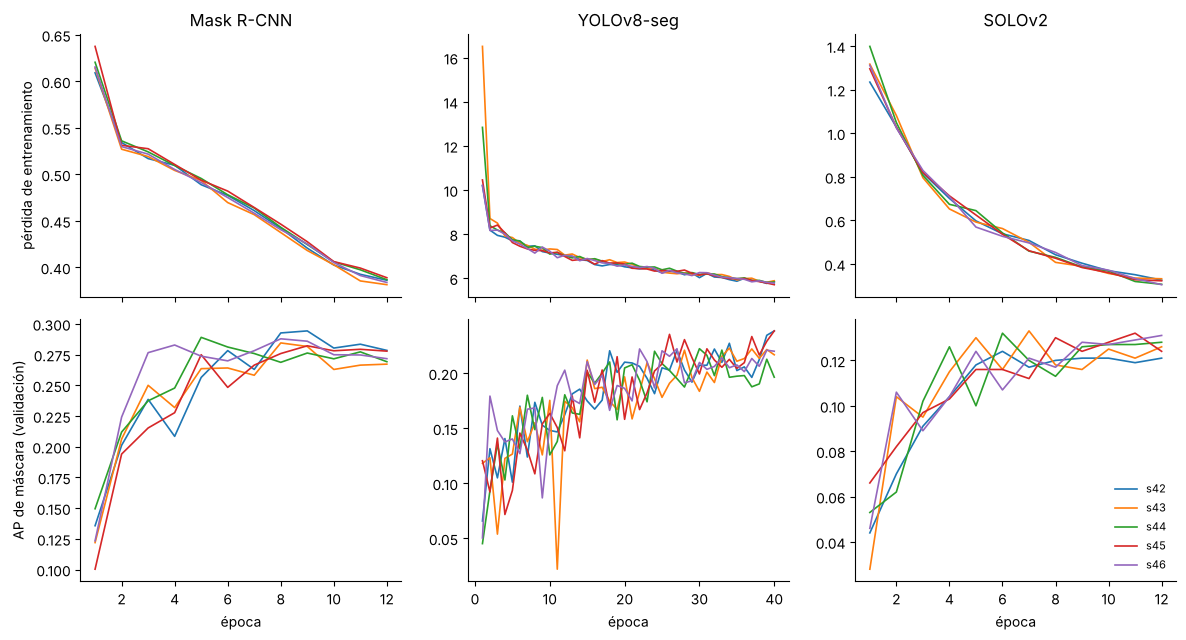

In [6]:
def curvas(d, m):
    if m == 'maskrcnn':
        h = pd.read_csv(d / 'historial.csv')
        return h.epoca, h.perdida, h.epoca, h.val_AP
    if m == 'yolov8seg':
        h = pd.read_csv(d / 'ultra' / 'results.csv'); h.columns = h.columns.str.strip()
        perd = h[['train/box_loss', 'train/seg_loss', 'train/cls_loss', 'train/dfl_loss']].sum(axis=1)
        return h.epoch, perd, h.epoch, h['metrics/mAP50-95(M)']
    escal = max(d.glob('*/vis_data/scalars.json'), key=lambda p: p.stat().st_size)
    filas = [json.loads(l) for l in escal.read_text(encoding='utf8').splitlines() if l.strip()]
    tr = pd.DataFrame([f for f in filas if 'loss' in f]).groupby('epoch').loss.mean()
    va = pd.DataFrame([f for f in filas if 'coco/segm_mAP' in f])
    return tr.index, tr.values, va.step, va['coco/segm_mAP']

orden = ['maskrcnn', 'yolov8seg', 'solov2']
fig, ax = plt.subplots(2, 3, figsize=(12, 6.5), sharex='col')
for j, m in enumerate(orden):
    for d in sorted(CORR.glob(f'{m}_s*')):
        e1, perd, e2, ap = curvas(d, m)
        s = d.name.rsplit('_s', 1)[1]
        ax[0, j].plot(e1, perd, lw=1.2, label=f's{s}')
        ax[1, j].plot(e2, ap, lw=1.2, label=f's{s}')
    ax[0, j].set_title(MODELOS[m]); ax[1, j].set_xlabel('época')
    for a in ax[:, j]:
        a.spines[['top', 'right']].set_visible(False)
ax[0, 0].set_ylabel('pérdida de entrenamiento'); ax[1, 0].set_ylabel('AP de máscara (validación)')
ax[1, 2].legend(frameon=False, fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

**Lectura (observada en la figura).**
- **Pérdida de entrenamiento.** Baja de forma monótona en los tres modelos, y las 5 semillas siguen trayectorias casi idénticas.
- **Mask R-CNN.** El AP de validación sube hasta las épocas 8 y 9 (≈ 0.29) y después se aplana o cae un poco (≈ 0.27), mientras la pérdida sigue bajando: es un sobreajuste leve al final. La selección por validación se queda con la mejor época.
- **YOLOv8-seg.** El AP de validación sigue subiendo en la época 40 y oscila bastante de una época a otra. Con más épocas probablemente mejoraría, así que el presupuesto fijo lo deja en desventaja (ver limitaciones).
- **SOLOv2.** Llega a ≈ 0.12 hacia la época 5 y después se queda entre 0.11 y 0.13. Más épocas no parecen capaces de cerrar la distancia con los otros dos.

No hay métricas en el conjunto de entrenamiento, así que la brecha entre entrenamiento y validación se juzga por la forma de las curvas, no con un número.

## 4.5 Estudio piloto y dimensionamiento (a posteriori)

El enunciado pide un estudio piloto con al menos 5 semillas por modelo sobre validación, previo a la ejecución definitiva. **No se hizo antes.** Por el calendario, las 5 semillas definitivas se lanzaron directamente. Se reporta aquí el mismo cálculo hecho con esas 5 semillas, sobre validación, como dimensionamiento a posteriori y como punto de partida para el número de semillas del E2. Las corridas se emparejan por semilla, como pide el enunciado.

**Tabla 4.4.** F1 de instancia por imagen en validación: media, desviación estándar y coeficiente de variación sobre las 5 semillas.

In [7]:
from itertools import combinations
DELTA = 0.2
filas = []
for d in sorted(CORR.glob('*_s*')):
    mod, s = d.name.rsplit('_s', 1)
    m = json.loads((d / 'metricas.json').read_text(encoding='utf8'))
    filas.append({'modelo': mod, 'semilla': int(s), 'F1_val': m['val']['F1_img']})
val = pd.DataFrame(filas).pivot(index='semilla', columns='modelo', values='F1_val')[orden]
piloto = val.agg(['mean', 'std']).T.rename(columns={'mean': 'media', 'std': 'DE'})
piloto['CV (%)'] = 100 * piloto['DE'] / piloto['media']
display(piloto.rename(index=MODELOS).round(4))

,media,DE,CV (%)
modelo,,,
Mask R-CNN,0.6584,0.0224,3.3993
YOLOv8-seg,0.6842,0.0356,5.1956
SOLOv2,0.4019,0.0106,2.6463


**Tabla 4.5.** Dimensionamiento por par: $\hat\sigma_d$ es la desviación estándar de las diferencias pareadas por semilla; $R \approx (z_{0.975} + z_{0.80})^2\, \hat\sigma_d^2 / \delta^2$ es el número de corridas necesario para detectar δ = 0.20 con potencia 0.80 y α = 0.05; el MDE es la menor diferencia detectable con las 5 corridas hechas.

In [8]:
z = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
filas = []
for a, b in combinations(orden, 2):
    dif = val[a] - val[b]; sd = dif.std(ddof=1)
    filas.append({'par': f'{MODELOS[a]} − {MODELOS[b]}', 'dif. media (val)': dif.mean(), 'σd': sd,
                  'δ/σd': DELTA / sd, 'R necesarias': int(np.ceil(z**2 * sd**2 / DELTA**2)),
                  'MDE con 5 corridas': z * sd / np.sqrt(len(dif)), 'Shapiro–Wilk p': stats.shapiro(dif).pvalue})
display(pd.DataFrame(filas).round(4))

par,dif. media (val),σd,δ/σd,R necesarias,MDE con 5 corridas,Shapiro–Wilk p
Mask R-CNN − YOLOv8-seg,-0.0259,0.0260,7.6796,1,0.0326,0.4090
Mask R-CNN − SOLOv2,0.2564,0.0181,11.0596,1,0.0227,0.3702
YOLOv8-seg − SOLOv2,0.2823,0.0282,7.0999,1,0.0353,0.1479


**Lectura del piloto.**
- La variabilidad entre semillas es baja (CV de 2,6 % a 5,2 %). Con δ = 0,20, la aproximación normal de la tabla 4.5 da menos de una corrida para cada par; al redondear hacia arriba resulta R = 1. Este cálculo no reemplaza las cinco semillas usadas para estimar la variabilidad.
- El MDE entre semillas queda entre 0,023 y 0,035, menor que δ.
- Shapiro–Wilk no rechaza la normalidad de las diferencias (p ≥ 0,15), aunque con cinco valores tiene poca potencia.

**La unidad de inferencia son los grupos de prueba.** Con 14 grupos, el MDE de Mask R-CNN frente a YOLOv8-seg es ≈ 0,10, menor que δ = 0,20. Aumentar el número de escenas en el E2 permitirá generalizar a más situaciones y compensar la corrección por comparaciones múltiples.
